# Detekcja znaków i świateł

Propozycje ramek powstają z masek HSV, konturów i krawędzi. Random Forest rozpoznaje znak, światło lub tło na podstawie geometrii, koloru, tekstury LBP i kierunków krawędzi. Kolor światła wyznaczamy z maski HSV.


In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from utils_common import *

ROOT = Path.cwd()
N, SEED = 1500, 42
EXP = ROOT / 'outputs' / f'official_{N}_seed{SEED}'
manifest = make_manifest(ROOT, EXP / 'manifest.json', N, SEED)
splits = manifest['splits']
print({name: len(records) for name, records in splits.items()})
from utils_detector import *


{'train': 1050, 'val': 150, 'test': 300}


## Propozycje ramek

Recall propozycji ogranicza możliwy recall całego detektora. Propozycje powstają bez dostępu do adnotacji.


,class,covered_GT,all_GT,proposal_recall
0,traffic_sign,105,474,0.221519
1,traffic_light,70,413,0.169492


Propozycje: 97


<Axes: title={'center': 'Propozycje'}>

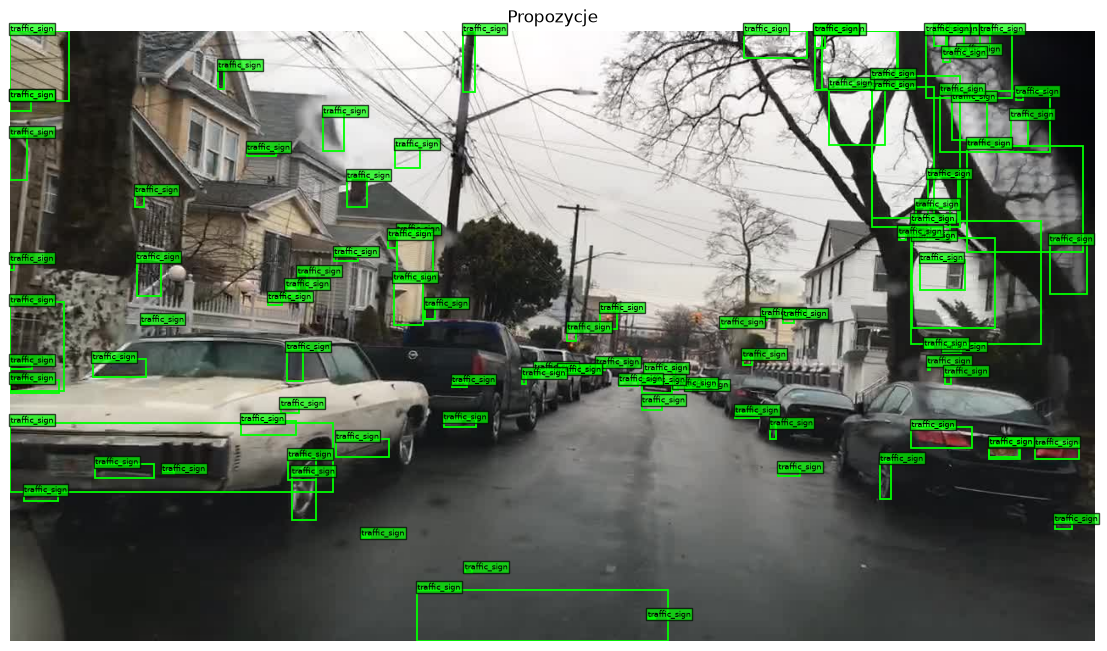

In [2]:
display(proposal_recall(ROOT, splits['val']))
r = splits['train'][0]
im = load_image(ROOT / r['image'])
boxes = proposals(im)
print('Propozycje:', len(boxes))
draw(im, [{'class': 'traffic_sign', 'box': b} for b in boxes], 'Propozycje')


## Cechy i trening

Trening używa ramek referencyjnych, ich niewielkich przesunięć oraz wycinków tła. Walidacja i test korzystają wyłącznie z rzeczywistych propozycji.


In [3]:
X, y, _ = feature_table(ROOT, splits['train'], training=True, seed=SEED)
V, vy, _ = feature_table(ROOT, splits['val'], training=False, seed=SEED)
print('Train:', X.shape, pd.Series(y).value_counts().to_dict())
print('Val:', V.shape, pd.Series(vy).value_counts().to_dict())
model = train_forest(X, y, SEED)
display(pd.Series(model.feature_importances_, index=X.columns).sort_values(ascending=False).head(20))


Cechy: 100/1050 obrazów; 3807 wycinków
Cechy: 200/1050 obrazów; 7583 wycinków
Cechy: 300/1050 obrazów; 11362 wycinków
Cechy: 400/1050 obrazów; 15074 wycinków
Cechy: 500/1050 obrazów; 18856 wycinków
Cechy: 600/1050 obrazów; 22475 wycinków
Cechy: 700/1050 obrazów; 26335 wycinków
Cechy: 800/1050 obrazów; 30129 wycinków
Cechy: 900/1050 obrazów; 33814 wycinków
Cechy: 1000/1050 obrazów; 37442 wycinków
Cechy: 100/150 obrazów; 7825 wycinków
Train: (39404, 63) {'background': 25200, 'traffic_sign': 7951, 'traffic_light': 6253}
Val: (11785, 63) {'background': 11596, 'traffic_sign': 115, 'traffic_light': 74}


geometry.aspect         0.074092
geometry.center_y       0.072497
geometry.width          0.042254
geometry.area           0.027965
color.v_hist_07         0.027373
color.v_hist_06         0.024394
edges.magnitude         0.023910
color.s_hist_05         0.022526
geometry.height         0.022098
color.s_hist_04         0.021977
texture.gray_std        0.021491
color.fraction_green    0.020962
texture.lbp_08          0.020751
color.s_hist_03         0.019275
texture.lbp_03          0.018726
edges.orientation_08    0.018595
edges.orientation_00    0.018168
edges.orientation_02    0.017881
texture.lbp_01          0.017315
color.fraction_white    0.016642
dtype: float64

## Dobór progu na walidacji

Próg wybieramy według średniego F1 dla obu klas przy IoU ≥ 0,5.


In [4]:
val_predictions = predict_records(ROOT, splits['val'], model, list(X.columns), threshold=0.)
results = []
for threshold in [.3, .4, .5, .6, .7]:
    filtered = {key: [p for p in value if p['score'] >= threshold] for key, value in val_predictions.items()}
    result = evaluate(ROOT, splits['val'], Params(), predictions=filtered)
    results.append({'threshold': threshold, 'mean_F1': result['metrics']['F1'].mean()})
validation = pd.DataFrame(results).sort_values('mean_F1', ascending=False)
display(validation)
threshold = float(validation.iloc[0]['threshold'])


Detekcja RF: 50/150
Detekcja RF: 100/150
Detekcja RF: 150/150


,threshold,mean_F1
3,0.6,0.121710
2,0.5,0.111666
1,0.4,0.107297
4,0.7,0.105697
0,0.3,0.104031


## Ocena na teście

Dopasowujemy każdą predykcję do najwyżej jednej ramki tej samej klasy. Macierz kolorów dotyczy tylko poprawnie zlokalizowanych świateł.


In [5]:
predictions = predict_records(ROOT, splits['test'], model, list(X.columns), threshold)
result = evaluate(ROOT, splits['test'], Params(), predictions=predictions)
display(result['metrics'])
display(result['confusion'].rename_axis(index='Kolor GT', columns='Kolor predykcji'))
print('Poprawnie zlokalizowane światła:', result['matched_lights'])
print('Dokładność koloru:', result['color_accuracy'])

save_json(EXP / 'simple_rf_predictions.json', {'threshold': threshold, 'predictions': predictions})


Detekcja RF: 50/300
Detekcja RF: 100/300
Detekcja RF: 150/300
Detekcja RF: 200/300
Detekcja RF: 250/300
Detekcja RF: 300/300


,class,TP,FP,FN,precision,recall,F1
0,traffic_sign,87,303,890,0.223077,0.089048,0.127286
1,traffic_light,78,431,706,0.153242,0.099490,0.120650


Kolor predykcji,red,yellow,green,unknown
Kolor GT,,,,
red,12,0,0,1
yellow,0,1,0,0
green,0,2,50,0
unknown,0,12,0,0


Poprawnie zlokalizowane światła: 78
Dokładność koloru: 0.8076923076923077


## Czas działania

Średni czas detekcji lasu na CPU: pierwsze 100 obrazów testowych, wczytane wcześniej, jedna detekcja na rozgrzewkę. Wartość trafia do porównania w lab5.

In [6]:
import time

ims = [load_image(ROOT / r['image']) for r in splits['test'][:100]]
cols = list(X.columns)
rf_detect(ims[0], model, cols, threshold)
t0 = time.perf_counter()
for im in ims:
    rf_detect(im, model, cols, threshold)
fps = len(ims) / (time.perf_counter() - t0)
print('FPS (CPU):', round(fps, 1))
save_json(EXP / 'rf_fps.json', {'fps': fps, 'images': len(ims), 'threshold': threshold})

FPS (CPU): 3.8


## Przykład i błędy


,id,type,class,box
0,d8960a48-e680b52f,FP,traffic_sign,"[617, 330, 658, 344]"
1,d8960a48-e680b52f,FP,traffic_sign,"[715, 347, 746, 357]"
2,d8960a48-e680b52f,FP,traffic_sign,"[1029, 222, 1049, 247]"
3,d8960a48-e680b52f,FN,traffic_sign,"[826.013176, 288.231184, 842.233979, 305.69974]"
4,d8960a48-e680b52f,FN,traffic_light,"[734.927131, 308.195249, 742.413655, 321.920543]"
5,d8960a48-e680b52f,FN,traffic_light,"[693.751248, 305.69974, 701.237772, 320.672789]"
6,d8960a48-e680b52f,FN,traffic_light,"[646.336594, 304.451986, 655.070872, 319.425035]"
7,cb1d8d95-283dd8d2,FN,traffic_sign,"[402.299858, 225.449921, 421.19985, 241.649918]"
8,cb1d8d95-283dd8d2,FN,traffic_sign,"[370.08549, 161.729944, 403.835481, 187.379934]"
9,cb1d8d95-283dd8d2,FN,traffic_light,"[618.485402, 232.19992, 638.735395, 247.049915]"


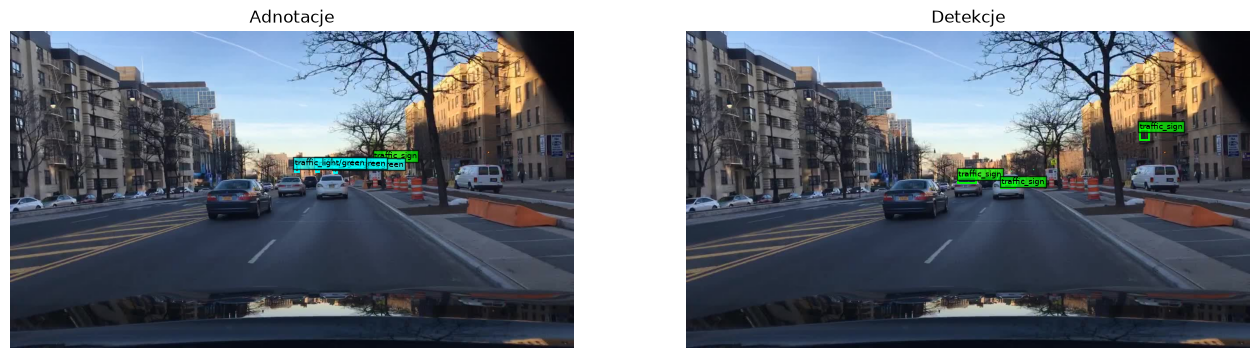

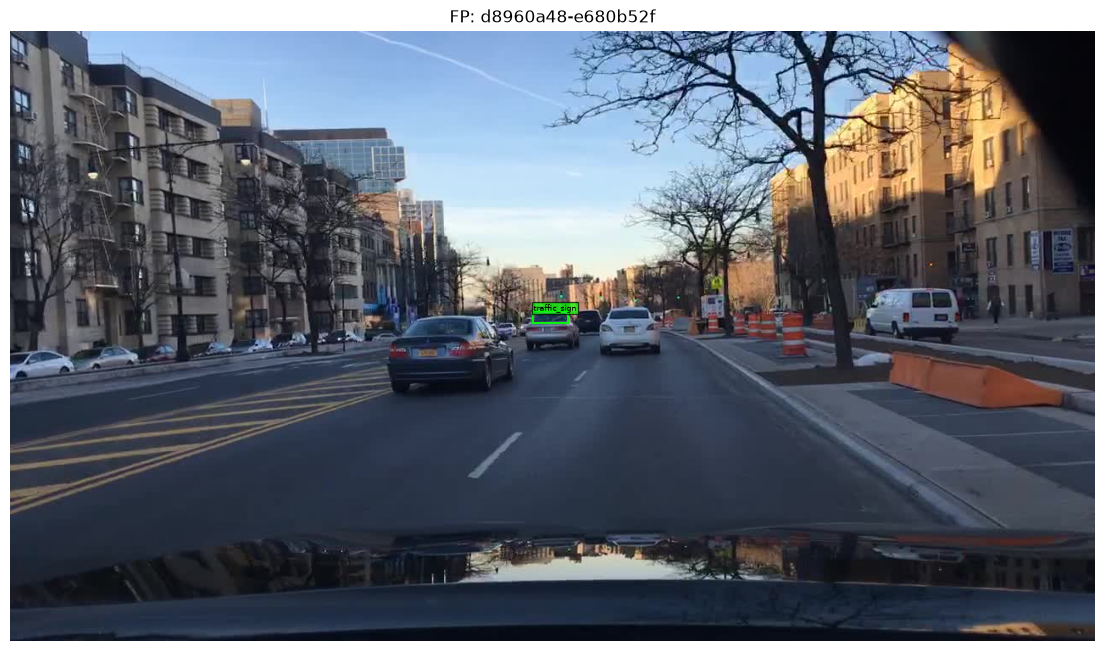

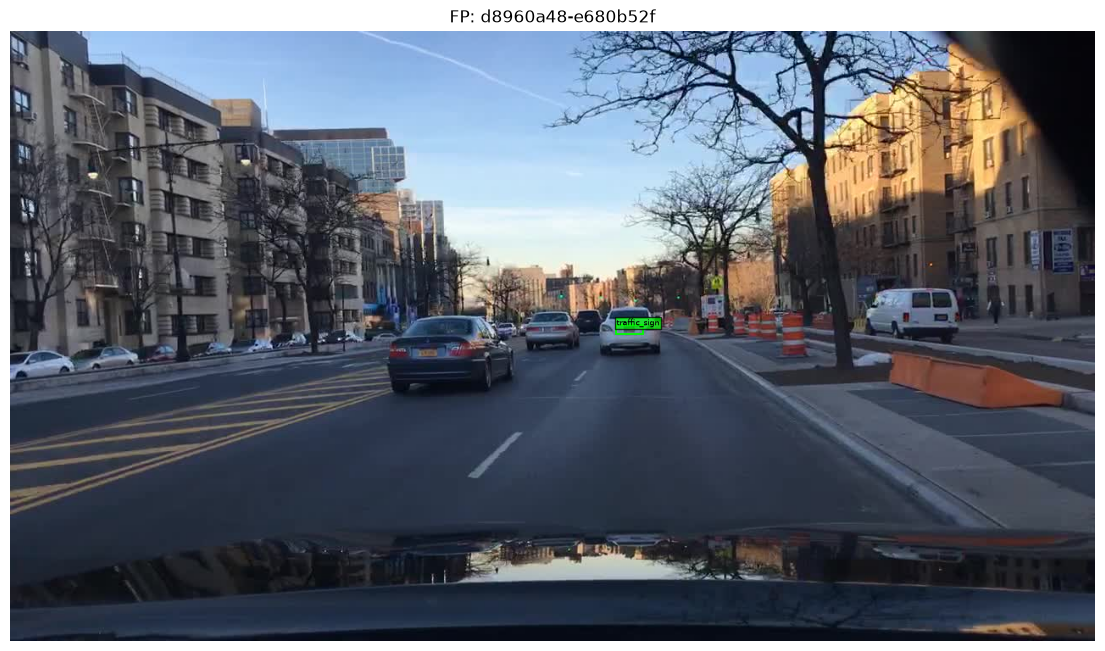

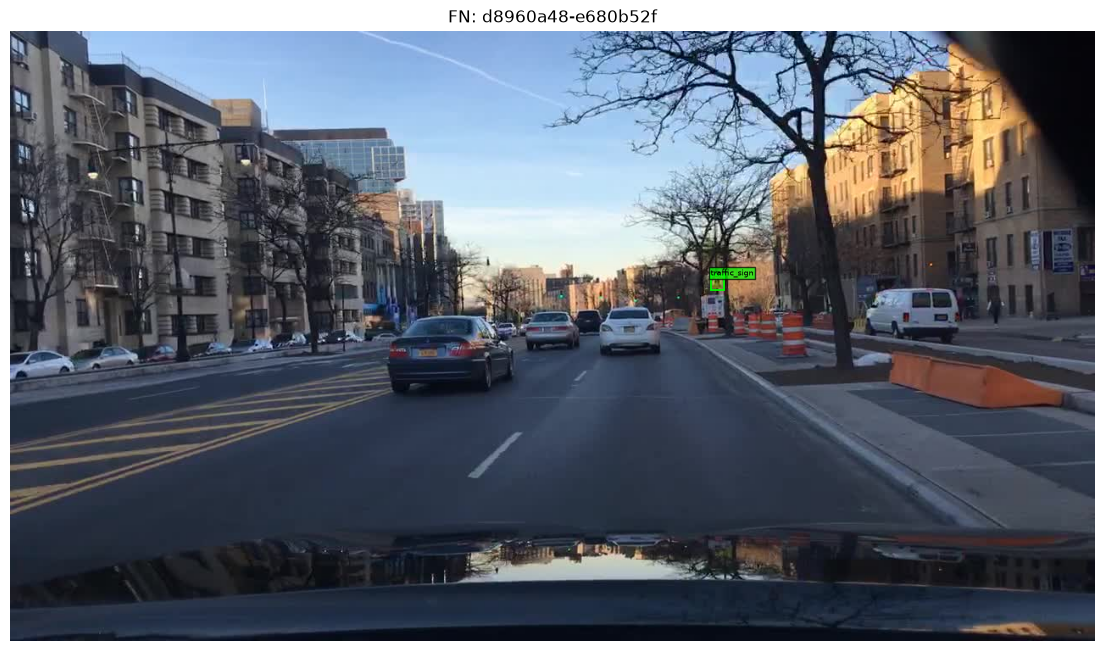

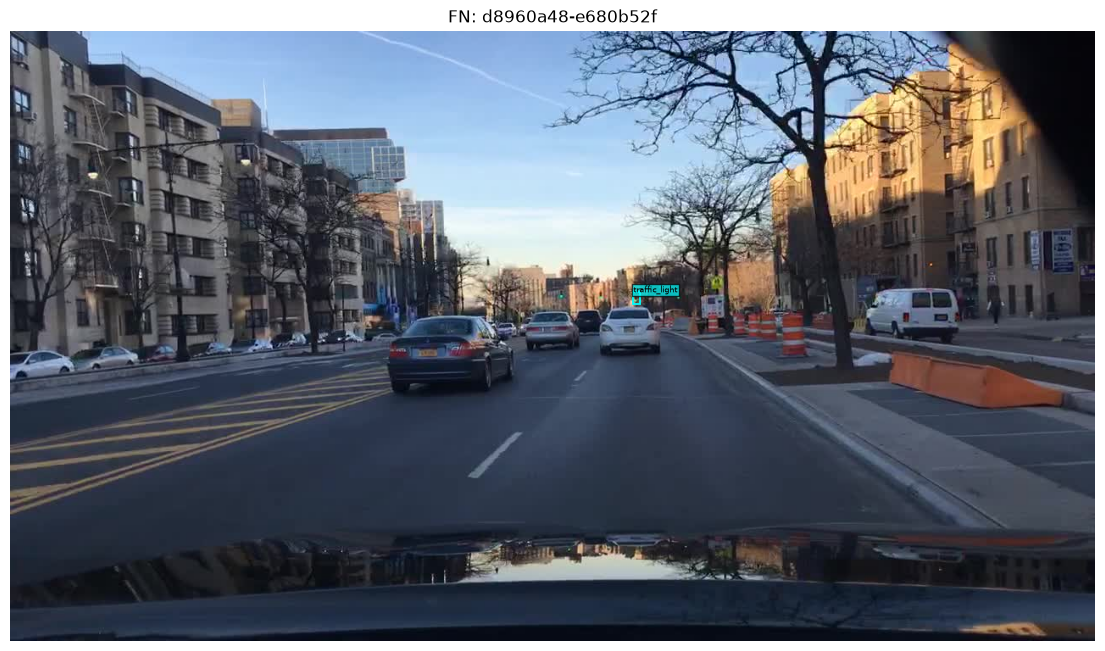

In [7]:
r = splits['test'][0]
im = load_image(ROOT / r['image'])
truth, _, _ = annotations(ROOT / r['label'], im.shape)
fig, axes = plt.subplots(1, 2, figsize=(16, 6))
draw(im, truth, 'Adnotacje', axes[0])
draw(im, predictions[r['id']], 'Detekcje', axes[1])
display(pd.DataFrame(result['errors']).head(20))

# Po dwa obrazy z FP i FN; zielona/cyjanowa ramka wskazuje błąd.
lookup = {r['id']: r for r in splits['test']}
for kind in ('FP', 'FN'):
    examples = [e for e in result['errors'] if e['type'] == kind][:2]
    for error in examples:
        record = lookup[error['id']]
        image = load_image(ROOT / record['image'])
        draw(image, [error], f"{kind}: {error['id']}")
        plt.show()


## Analiza błędów

Na obrazie `d8960a48-e680b52f` dwa pokazane FP to fragmenty samochodów oznaczone jako znaki. Jasne prostokątne detale i krawędzie samochodu mogą przypominać wycinki znaków, przez co klasyfikator nadaje im zbyt wysokie prawdopodobieństwo. Pokazane FN to mały znak i sygnalizator widoczne w oddali; przy ich niewielkich rozmiarach kształt i kolor są trudne do rozróżnienia, a ramka propozycji łatwo mija się z adnotacją. To możliwe przyczyny, nie rozstrzygamy tutaj, czy dany FN wynika z braku propozycji, klasyfikacji czy progu.

Przykłady pochodzą z jednego obrazu, więc nie opisują wszystkich rodzajów błędów. Warto obejrzeć więcej scen, zwłaszcza nocnych i deszczowych, oraz sprawdzić osobno, czy dla pominiętych obiektów w ogóle powstała ramka o IoU ≥ 0,5.

## Wnioski

Na walidacji największe średnie F1 dla dwóch klas uzyskano dla progu **0,6**: 0,122. Ten próg zastosowano następnie do 300 obrazów testowych. Przy IoU ≥ 0,5 wyniki wynoszą:

| Klasa | TP | FP | FN | Precision | Recall | F1 |
|---|---:|---:|---:|---:|---:|---:|
| Znaki | 87 | 303 | 890 | 0,223 | 0,089 | 0,127 |
| Sygnalizatory | 78 | 431 | 706 | 0,153 | 0,099 | 0,121 |

Wyniki są słabe: detektor pomija większość obiektów, a wiele zgłoszeń jest fałszywych. Głównym ograniczeniem są już same propozycje: na walidacji ramkę o IoU ≥ 0,5 otrzymało tylko 105 z 474 znaków (22,2%) oraz 70 z 413 świateł (16,9%). Jest to górna granica recall dla tego generatora i ocenianej próbki, przed dalszym odrzucaniem ramek przez klasyfikator i NMS.

Kolor określono poprawnie dla 63 z 78 poprawnie zlokalizowanych świateł (80,8%). Wynik dotyczy tylko tych 78 obiektów, a nie wszystkich sygnalizatorów. Macierz pokazuje m.in. 12 przypadków `unknown` oznaczonych jako żółte i tylko jeden poprawnie zlokalizowany żółty sygnalizator; wynik dla żółtego jest więc zbyt mały do wiarygodnej oceny. Różnica między nieokreślonym kolorem w adnotacji a widoczną barwą może wpływać na tę pomyłkę, ale wymaga obejrzenia przykładów.

Ważność cech lasu wskazuje m.in. na proporcje i pionowe położenie ramki, ale nie dowodzi związku przyczynowego ani skuteczności każdej grupy cech. W kolejnym eksperymencie warto poprawić pokrycie małych obiektów przez wieloskalowe propozycje i zbadać recall przed klasyfikacją, a następnie dodać trudne przykłady tła. Ostateczną ocenę zmian należy przeprowadzić ponownie na teście, pamiętając, że te wyniki testowe są już znane.


## Dalszy eksperyment: model i geometria

Las losowy jest punktem odniesienia, nie mamy podstaw uznać go za najlepszy. Poniżej porównujemy go z Extra Trees oraz regresją logistyczną ze skalowaniem cech. Dla lasu sprawdzamy też wariant bez położenia i rozmiaru. Wszystkie modele uczymy na tych samych wycinkach `train`, a model i próg porównujemy na obrazach `val` według średniego F1 detekcji, nie samej klasyfikacji wycinków. Komórka może działać długo. Wyniki testowe powyżej pozostają wynikami wcześniejszego lasu; po wybraniu nowego modelu potrzebna jest osobna ocena na niezależnym teście.


In [8]:
from sklearn.ensemble import ExtraTreesClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

all_columns = list(X.columns)
no_geometry = [c for c in all_columns if not c.startswith('geometry.')]
experiments = {
    'random forest': (model, all_columns),
    'random forest bez geometrii': (train_forest(X[no_geometry], y, SEED), no_geometry),
    'extra trees': (ExtraTreesClassifier(n_estimators=100, max_depth=18, min_samples_leaf=2,
                                        class_weight='balanced', random_state=SEED, n_jobs=-1).fit(X, y), all_columns),
    'regresja logistyczna': (make_pipeline(StandardScaler(), LogisticRegression(
        class_weight='balanced', max_iter=1000, random_state=SEED)).fit(X, y), all_columns),
}
comparison = []
for name, (candidate, columns) in experiments.items():
    raw = predict_records(ROOT, splits['val'], candidate, columns, threshold=0.)
    for t in [.3, .4, .5, .6, .7]:
        filtered = {key: [p for p in value if p['score'] >= t] for key, value in raw.items()}
        metrics = evaluate(ROOT, splits['val'], Params(), predictions=filtered)['metrics']
        comparison.append({'model': name, 'threshold': t,
                           'mean_F1': metrics['F1'].mean(),
                           'F1_sign': metrics.loc[metrics['class'] == 'traffic_sign', 'F1'].iloc[0],
                           'F1_light': metrics.loc[metrics['class'] == 'traffic_light', 'F1'].iloc[0]})
comparison = pd.DataFrame(comparison).sort_values('mean_F1', ascending=False)
display(comparison)


Detekcja RF: 50/150
Detekcja RF: 100/150
Detekcja RF: 150/150
Detekcja RF: 50/150
Detekcja RF: 100/150
Detekcja RF: 150/150
Detekcja RF: 50/150
Detekcja RF: 100/150
Detekcja RF: 150/150
Detekcja RF: 50/150
Detekcja RF: 100/150
Detekcja RF: 150/150


,model,threshold,mean_F1,F1_sign,F1_light
3,random forest,0.6,0.121710,0.130106,0.113314
12,extra trees,0.5,0.117058,0.128370,0.105747
2,random forest,0.5,0.111666,0.116757,0.106576
1,random forest,0.4,0.107297,0.119536,0.095057
4,random forest,0.7,0.105697,0.107407,0.103986
0,random forest,0.3,0.104031,0.116319,0.091743
8,random forest bez geometrii,0.6,0.098347,0.098039,0.098655
13,extra trees,0.6,0.097157,0.089385,0.104928
7,random forest bez geometrii,0.5,0.097020,0.098476,0.095563
6,random forest bez geometrii,0.4,0.094900,0.096565,0.093236


## Wnioski z porównania modeli

W tym porównaniu na 150 obrazach walidacyjnych najlepszy wynik uzyskał **Random Forest z geometrią**: średnie F1 = **0,122** przy progu 0,6 (znaki 0,130, światła 0,113). Najlepszy Extra Trees osiągnął 0,117 przy progu 0,5, a regresja logistyczna 0,063 przy progu 0,7. Różnica między dwoma lasami jest niewielka; wynik dotyczy tylko tych konfiguracji, progów i tego podziału, więc nie rozstrzyga, który algorytm jest ogólnie lepszy.

Najlepszy las bez cech geometrycznych osiągnął 0,098 przy progu 0,6, wobec 0,122 z geometrią. Na tej walidacji geometria pomaga: spadek dotyczy obu klas (F1 znaków 0,130 → 0,098; świateł 0,113 → 0,099). Usunięto jednak jednocześnie położenie, rozmiar, pole i proporcje, więc nie da się przypisać poprawy pojedynczej cesze ani stwierdzić, czy oddzielne ważenie heatmapą pomoże. Można to sprawdzić osobną ablacją położenia i rozmiaru, zachowując wariant bez ważenia jako punkt odniesienia.

Żaden wariant nie usuwa głównego ograniczenia: recall propozycji wynosi tylko 22,2% dla znaków i 16,9% dla świateł na tej samej walidacji. W pierwszej kolejności warto poprawić generator ramek, szczególnie dla małych obiektów, a dopiero potem ponownie porównać modele. Wyniki walidacyjne służyły wyborowi modelu i progu; poprzedni test jest już znany, więc niezależna ocena kolejnych decyzji wymaga nowego, wcześniej nieoglądanego zbioru.
